# Model 03 — Customer Lifetime Value Prediction
## 03. Modeling & Evaluation

### Objective
Compare a baseline with suitable regression models for the approved target `future_gross_purchase_value`.

**Data contract:** Run Notebook 02 first. It saves `data/processed/clv_customer_features_and_targets.csv`. Predictors must use observation-window features only; `Customer ID` and both target columns are excluded from `X`.

The target is highly right-skewed. This notebook reports MAE, RMSE and R² on the original currency scale. Model selection must consider errors and business interpretation, not R² alone.


## 1. Imports, paths and load the approved dataset

Run from `ml/model_03_customer_lifetime_value/notebooks/`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

MODEL_ROOT = Path.cwd().parent
DATASET_PATH = MODEL_ROOT / "data" / "processed" / "clv_customer_features_and_targets.csv"

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"{DATASET_PATH} not found. Run Notebook 02 and execute its final save cell first."
    )

data = pd.read_csv(DATASET_PATH)
TARGET = "future_gross_purchase_value"
TARGET_COLUMNS = ["future_gross_purchase_value", "future_net_transaction_value"]
ID_COLUMN = "Customer ID"

required = [ID_COLUMN, TARGET, *TARGET_COLUMNS]
missing = [col for col in required if col not in data.columns]
if missing:
    raise KeyError(f"Required columns missing: {missing}")

feature_columns = [
    "observation_invoice_count",
    "observation_total_value",
    "observation_average_invoice_value",
    "observation_median_invoice_value",
    "observation_total_quantity",
    "observation_product_line_count",
    "recency_days",
    "customer_tenure_days",
    "average_days_between_observed_purchases",
]
missing_features = [col for col in feature_columns if col not in data.columns]
if missing_features:
    raise KeyError(f"Expected feature columns missing: {missing_features}")

print("Dataset shape:", data.shape)
print("Primary target:", TARGET)
print("Feature count:", len(feature_columns))
print("Missing primary targets:", int(data[TARGET].isna().sum()))
print("Customers with zero target:", int(data[TARGET].eq(0).sum()))
display(data[[TARGET]].describe(percentiles=[.5, .75, .9, .95, .99]).T)


Dataset shape: (4266, 14)
Primary target: future_gross_purchase_value
Feature count: 9
Missing primary targets: 0
Customers with zero target: 1553


,count,mean,std,min,50%,75%,90%,95%,99%,max
future_gross_purchase_value,"4,266.00","1,685.32","8,614.19",0.00,325.01,"1,317.17","3,341.30","5,511.72","17,275.16","276,006.37"


## 2. Prepare features and hold-out test set

The split is across customers because every row already uses the same historical observation window and the same future target window. This is a customer-level holdout, not a second temporal backtest. Missing feature values are imputed inside each model pipeline to avoid fitting preprocessing on the test set.

In [2]:
X = data[feature_columns].copy()
y = data[TARGET].astype(float).copy()

if (y < 0).any():
    raise ValueError("Primary gross purchase-value target should not be negative; inspect Notebook 02.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training customers:", f"{len(X_train):,}")
print("Test customers:", f"{len(X_test):,}")
print("Train target mean:", f"{y_train.mean():,.2f}")
print("Test target mean:", f"{y_test.mean():,.2f}")


Training customers: 3,412
Test customers: 854
Train target mean: 1,690.96
Test target mean: 1,662.81


## 3. Train baseline and candidate regression models

Compare a naive mean baseline, a regularized linear model, and tree-based models. All preprocessing is fitted using training data only.

In [3]:
models = {
    "Dummy mean baseline": Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("model", DummyRegressor(strategy="mean")),
    ]),
    "Ridge regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0)),
    ]),
    "Random forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("model", RandomForestRegressor(
            n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1
        )),
    ]),
    "HistGradientBoosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("model", HistGradientBoostingRegressor(
            max_iter=200, learning_rate=0.08, l2_regularization=1.0, random_state=42
        )),
    ]),
}

results = []
fitted_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    predictions = np.maximum(predictions, 0)  # purchase value cannot be negative
    fitted_models[name] = model
    results.append({
        "model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions),
    })

results_df = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)
display(results_df)


,model,MAE,RMSE,R2
0,Random forest,"1,133.39","5,154.02",0.73
1,HistGradientBoosting,"1,189.43","5,333.67",0.71
2,Ridge regression,"1,258.67","3,916.96",0.84
3,Dummy mean baseline,"2,111.91","9,831.89",-0.00


## 4. Inspect target skew and prediction errors

MAE is the primary comparison metric because it is expressed in the same currency units as the target. RMSE highlights large errors; R² is supplementary. A small number of high-value customers can dominate RMSE, so inspect errors and residual patterns before selecting a model.

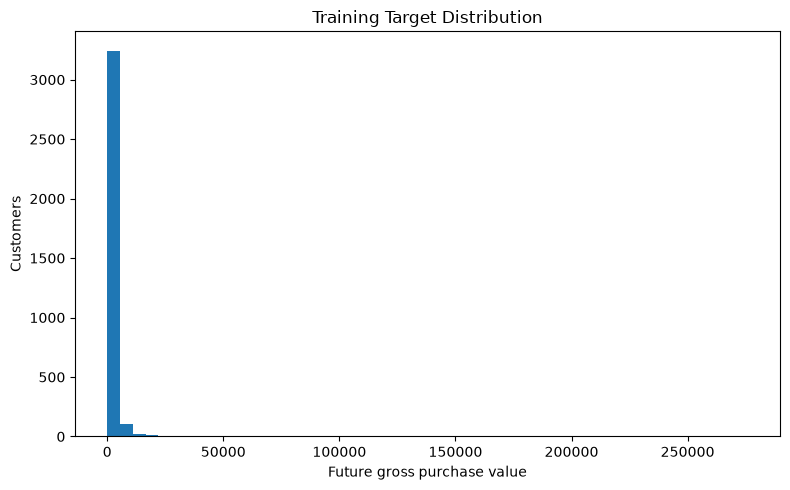

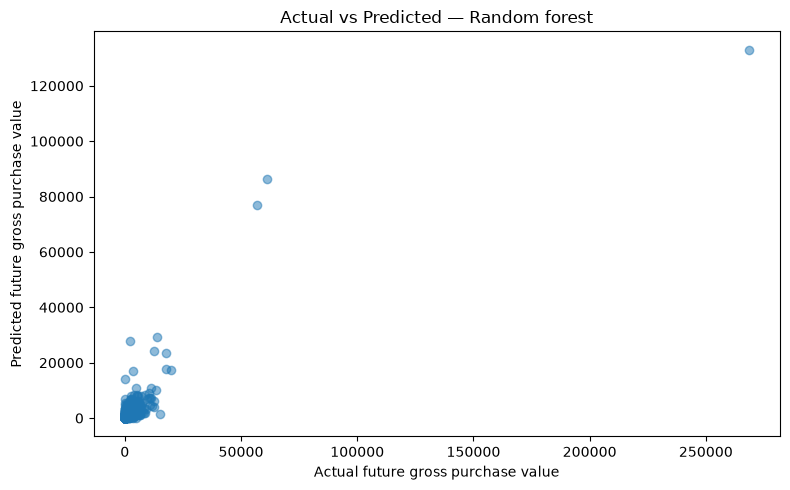

,count,mean,std,min,25%,50%,75%,max
actual,854.00,"1,662.81","9,837.61",0.00,0.00,323.98,"1,342.20","268,478.00"
predicted,854.00,"1,699.01","6,474.24",2.63,263.37,565.68,"1,381.93","133,019.63"
absolute_error,854.00,"1,133.39","5,030.81",0.58,156.98,394.26,988.09,"135,458.37"


Lowest test MAE model (provisional): Random forest


In [4]:
best_name = results_df.iloc[0]["model"]
best_model = fitted_models[best_name]
best_predictions = np.maximum(best_model.predict(X_test), 0)

plt.figure(figsize=(8, 5))
plt.hist(y_train, bins=50)
plt.xlabel("Future gross purchase value")
plt.ylabel("Customers")
plt.title("Training Target Distribution")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(y_test, best_predictions, alpha=0.5)
plt.xlabel("Actual future gross purchase value")
plt.ylabel("Predicted future gross purchase value")
plt.title(f"Actual vs Predicted — {best_name}")
plt.tight_layout()
plt.show()

error_summary = pd.DataFrame({
    "actual": y_test.to_numpy(),
    "predicted": best_predictions,
})
error_summary["absolute_error"] = (error_summary["actual"] - error_summary["predicted"]).abs()
display(error_summary.describe().T)
print("Lowest test MAE model (provisional):", best_name)


## 5. Evaluation notes and next steps

- Compare every candidate with the dummy baseline; if improvements are small, do not claim the complex model is better.
- Inspect actual-vs-predicted plots and large errors, especially for high-value customers.
- The random customer holdout estimates performance for customers sampled from this fixed cohort; it does **not** establish performance across later calendar periods. A second temporal backtest would require another valid observation/target split.
- Do not call the target true lifetime value. It is future gross purchase value over a fixed one-year horizon.
- Model selection remains provisional until results and error analysis are reviewed in context.
- Save the selected model only after review; final model packaging and explainability belong in Notebook 04.


## 6. Error analysis by customer outcome

The overall MAE hides an important business distinction: customers with zero future purchases versus customers who purchase again. Review both groups separately before choosing a model. This does not change the approved target; it helps explain where prediction errors occur.


In [5]:
# Evaluate each candidate separately for zero and positive future-value customers

segment_rows = []
for name, model in fitted_models.items():
    pred = np.maximum(model.predict(X_test), 0)
    for segment_name, mask in [
        ("Zero future value", y_test.to_numpy() == 0),
        ("Positive future value", y_test.to_numpy() > 0),
    ]:
        if mask.sum() == 0:
            continue
        segment_rows.append({
            "model": name,
            "customer_segment": segment_name,
            "customers": int(mask.sum()),
            "MAE": mean_absolute_error(y_test.to_numpy()[mask], pred[mask]),
            "RMSE": np.sqrt(mean_squared_error(y_test.to_numpy()[mask], pred[mask])),
        })

segment_results = pd.DataFrame(segment_rows).sort_values(
    ["customer_segment", "MAE"]
).reset_index(drop=True)
display(segment_results)


,model,customer_segment,customers,MAE,RMSE
0,Random forest,Positive future value,536,"1,471.05","6,437.85"
1,Ridge regression,Positive future value,536,"1,525.74","4,342.76"
2,HistGradientBoosting,Positive future value,536,"1,534.00","6,560.96"
3,Dummy mean baseline,Positive future value,536,"2,361.66","12,341.80"
4,Random forest,Zero future value,318,564.25,"1,216.51"
5,HistGradientBoosting,Zero future value,318,608.63,"1,960.21"
6,Ridge regression,Zero future value,318,808.52,"3,068.30"
7,Dummy mean baseline,Zero future value,318,"1,690.96","1,690.96"


## 7. Error analysis across target-value bands

High-value customers can dominate RMSE and may be difficult to estimate accurately. The table below groups test customers by their actual future value so we can see whether a model performs well mainly on low-value customers while missing the tail.


In [6]:
# Evaluate the provisional lowest-MAE model across actual-value bands

band_data = pd.DataFrame({
    "actual": y_test.to_numpy(),
    "predicted": best_predictions,
})
band_data["absolute_error"] = (band_data["actual"] - band_data["predicted"]).abs()
band_data["actual_value_band"] = pd.cut(
    band_data["actual"],
    bins=[-0.01, 0, 500, 2000, 10000, np.inf],
    labels=["Zero", "(0, 500]", "(500, 2,000]", "(2,000, 10,000]", "> 10,000"],
    include_lowest=True,
)

band_summary = band_data.groupby(
    "actual_value_band", observed=False
).agg(
    customers=("actual", "size"),
    mean_actual=("actual", "mean"),
    mean_predicted=("predicted", "mean"),
    MAE=("absolute_error", "mean"),
).reset_index()

display(band_summary)


,actual_value_band,customers,mean_actual,mean_predicted,MAE
0,Zero,318,0.00,564.25,564.25
1,"(0, 500]",171,269.24,560.08,324.74
2,"(500, 2,000]",204,"1,057.39","1,151.17",703.47
3,"(2,000, 10,000]",142,"3,947.62","3,241.67","2,222.45"
4,"> 10,000",19,"31,459.37","25,294.19","14,413.55"


## 8. Model selection review

Current hold-out results show a trade-off:
- Random Forest has the lowest MAE, so it is the provisional candidate if average absolute currency error is the main priority.
- Ridge has the lowest RMSE and highest R², suggesting better aggregate fit under squared-error evaluation.
- The target is highly skewed and contains very large future values, so neither metric alone settles the choice.

Review the segment and value-band tables above before locking a model. The random customer split is not a temporal backtest, so the selected model's results should be described as preliminary hold-out performance.


In [7]:
# Save the evaluation tables for reproducible review
OUTPUT_DIR = MODEL_ROOT / "reports"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results_df.to_csv(OUTPUT_DIR / "clv_model_comparison.csv", index=False)
segment_results.to_csv(OUTPUT_DIR / "clv_error_by_customer_outcome.csv", index=False)
band_summary.to_csv(OUTPUT_DIR / "clv_error_by_actual_value_band.csv", index=False)

print("Saved evaluation tables to:", OUTPUT_DIR)


Saved evaluation tables to: d:\MCA PU\Semesters\Semester 3\MCA_Projects\the-enterprise-ai-decision-intelligence-platform\ml\model_03_customer_lifetime_value\reports
